# Sentinel Auth — RBA benchmark

Thí nghiệm này kiểm chứng đúng sáu feature cố định của Sentinel trên 10 triệu login đầu của RBA. Mọi feature chỉ dùng lịch sử trước sự kiện hiện tại; nhãn chỉ dùng cho đánh giá và Logistic Regression `DIAGNOSTIC_ONLY`.

In [1]:
from collections import Counter, deque
from datetime import datetime, timezone
from pathlib import Path
from threading import Event, Thread
from time import perf_counter
import gc
import json
import platform

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression, SGDOneClassSVM
from sklearn.metrics import (
    average_precision_score, confusion_matrix, precision_recall_curve,
    precision_recall_fscore_support, roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler

## 00 — Cấu hình và tái lập

Baseline trước forensic được giữ nguyên trong `BASELINE_10M`. Semantics sửa đổi không thay tên, kiểu hoặc miền giá trị của sáu feature.

In [2]:
def progress(message):
    print(f'[{datetime.now(timezone.utc).isoformat()}] {message}', flush=True)

heartbeat_stop = Event()
def heartbeat():
    while not heartbeat_stop.wait(60):
        progress('heartbeat: notebook active')
Thread(target=heartbeat, daemon=True).start()

DATA_PATH = Path('/kaggle/input/datasets/dasgroup/rba-dataset/rba-dataset.csv')
OUTPUT_DIR = Path('/kaggle/working/sentinel-rba')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
NROWS = 10_000_000
TRAIN_RATIO = 0.80
RANDOM_STATE = 42
MODEL_VERSION = 'v1.1-isolation-forest-rba-corrected-experimental'
FEATURE_SEMANTICS_VERSION = 'sentinel-six-v1.1'
FEATURES = [
    'hour_of_day', 'fail_count_24h', 'ip_change_rate_7d', 'new_device',
    'average_login_interval_seconds', 'deviation_score',
]
TARGETS = ['Is Account Takeover', 'Is Attack IP']
BASELINE_10M = {
    'rows': 10_000_000, 'users': 2_075_123, 'train_rows': 8_000_000,
    'test_rows': 2_000_000, 'cutoff_utc': '2020-05-23T13:12:33.886000+00:00',
    'test_ato': 14, 'test_attack_ip': 185_355,
    'ato_if_ap': 0.000011, 'ato_if_ap_lift': 1.58, 'ato_if_roc_auc': 0.516,
    'ato_if_recall': 0.571, 'ato_if_flag_rate': 0.3676,
    'attack_ip_if_ap': 0.074625, 'attack_ip_if_roc_auc': 0.431,
    'if_temporal_roc_auc': [0.787, 0.457, 0.335, 0.538],
}
progress(f'python={platform.python_version()} sklearn={sklearn.__version__} rows={NROWS:,}')

[2026-10-25T15:44:36.834332+00:00] python=3.13.15 sklearn=1.6.1 rows=10,000,000


## 01 — Đọc RBA

Chỉ đọc các trường cần để dựng sáu feature và hai nhãn. RTT, vị trí và ASN hợp lệ trong RBA nhưng nằm ngoài contract Sentinel.

In [3]:
progress('load: start')
columns = [
    'User ID', 'Login Timestamp', 'IP Address', 'User Agent String',
    'Login Successful', *TARGETS,
]
df = pd.read_csv(DATA_PATH, usecols=columns, nrows=NROWS, low_memory=False)
progress(f'load: complete shape={df.shape} memory_mib={df.memory_usage(deep=True).sum()/2**20:.1f}')
df.head()

[2026-10-25T15:44:36.852670+00:00] load: start
[2026-10-25T15:45:38.828953+00:00] load: complete shape=(10000000, 7) memory_mib=3241.0[2026-10-25T15:45:38.829088+00:00] heartbeat: notebook active



,Login Timestamp,User ID,IP Address,User Agent String,Login Successful,Is Attack IP,Is Account Takeover
0,2020-02-03 12:43:30.772,-4324475583306591935,10.0.65.171,Mozilla/5.0 (iPhone; CPU iPhone OS 13_4 like ...,False,False,False
1,2020-02-03 12:43:43.549,-4324475583306591935,194.87.207.6,Mozilla/5.0 (Linux; Android 4.1; Galaxy Nexus...,False,False,False
2,2020-02-03 12:43:55.873,-3284137479262433373,81.167.144.58,Mozilla/5.0 (iPad; CPU OS 7_1 like Mac OS X) ...,True,False,False
3,2020-02-03 12:43:56.180,-4324475583306591935,170.39.78.152,Mozilla/5.0 (Linux; Android 4.1; Galaxy Nexus...,False,False,False
4,2020-02-03 12:43:59.396,-4618854071942621186,10.0.0.47,Mozilla/5.0 (Linux; U; Android 2.2) Build/NMA...,False,True,False


## 02 — Kiểm tra nguồn và nhãn

In [4]:
progress('validation: start')
source_missing = df[columns].isna().sum().rename('missing')
df['Login Timestamp'] = pd.to_datetime(df['Login Timestamp'], utc=True, errors='coerce')
for column in ['Login Successful', *TARGETS]:
    if not pd.api.types.is_bool_dtype(df[column]):
        df[column] = (df[column].astype('string').str.lower()
                      .map({'true': True, 'false': False, '1': True, '0': False}))
before_drop = len(df)
df = df.dropna(subset=columns)
print(source_missing)
print('dropped rows:', before_drop - len(df))
print('label positives:', {target: int(df[target].sum()) for target in TARGETS})
progress('validation: complete')

[2026-10-25T15:45:38.873745+00:00] validation: start
User ID                0
Login Timestamp        0
IP Address             0
User Agent String      0
Login Successful       0
Is Account Takeover    0
Is Attack IP           0
Name: missing, dtype: int64
dropped rows: 0
label positives: {'Is Account Takeover': 69, 'Is Attack IP': 955482}
[2026-10-25T15:45:45.231517+00:00] validation: complete


## 03 — Lịch sử theo thời gian

Sắp xếp ổn định theo user và timestamp. Mọi cửa sổ sau đây đều là nửa kín `[lower_bound, current_timestamp)`.

In [5]:
progress('chronological sort: start')
df = df.sort_values(['User ID', 'Login Timestamp'], kind='mergesort').reset_index(drop=True)
assert df.groupby('User ID', sort=False)['Login Timestamp'].apply(
    lambda values: values.is_monotonic_increasing).all()
print(f'rows: {len(df):,} | users: {df["User ID"].nunique():,}')
progress('chronological sort: complete')

[2026-10-25T15:45:45.252582+00:00] chronological sort: start
[2026-10-25T15:46:38.989258+00:00] heartbeat: notebook active
rows: 10,000,000 | users: 2,075,123
[2026-10-25T15:47:21.864080+00:00] chronological sort: complete


## 04 — Sáu feature đã hiệu chỉnh

- `hour_of_day`: giờ UTC của event (`PROJECT_DEFINED_CONTRACT_CLARIFICATION`).
- `fail_count_24h`: lỗi của cùng user trong `[t-24h,t)`.
- `ip_change_rate_7d`: `1 - count(current IP)/count(prior logins)` trong `[t-7d,t)`; không lịch sử = 0 (`PROJECT_DEFINED_RBA_ADAPTATION`).
- `new_device`: exact User-Agent proxy chưa thấy trong `[t-30d,t)`; UA thiếu = false (`PROJECT_DEFINED_UA_PROXY`).
- `average_login_interval_seconds`: trung bình tối đa 9 khoảng cách từ 10 timestamp trước; thiếu lịch sử = 0 (`KEEP_PROJECT_DEFINED`).
- `deviation_score`: độ lệch tương đối của current gap so với trung bình trên, clip `[0,1]`; thiếu lịch sử = 0 (`KEEP_PROJECT_DEFINED`).

In [6]:
progress('vector features: start')
df['hour_of_day'] = df['Login Timestamp'].dt.hour.astype('int8')
df['_failed'] = (~df['Login Successful']).astype('int8')
df['fail_count_24h'] = (
    df.groupby('User ID', sort=False)
      .rolling('24h', on='Login Timestamp', closed='left')['_failed'].sum()
      .fillna(0).to_numpy().astype('int32')
)
df['_gap'] = df.groupby('User ID', sort=False)['Login Timestamp'].diff().dt.total_seconds()
df['average_login_interval_seconds'] = (
    df.groupby('User ID', sort=False)['_gap']
      .transform(lambda values: values.shift().rolling(9, min_periods=1).mean())
      .fillna(0).astype('int64')
)
historical_mean = df['average_login_interval_seconds']
df['deviation_score'] = (
    ((df['_gap'] - historical_mean).abs() / historical_mean.where(historical_mean.gt(0)))
    .fillna(0).clip(0, 1).astype('float32')
)
progress('vector features: complete')

[2026-10-25T15:47:21.888595+00:00] vector features: start
[2026-10-25T15:47:39.328617+00:00] heartbeat: notebook active
[2026-10-25T15:48:39.330423+00:00] heartbeat: notebook active
[2026-10-25T15:49:39.336051+00:00] heartbeat: notebook active
[2026-10-25T15:50:39.350671+00:00] heartbeat: notebook active
[2026-10-25T15:51:39.360549+00:00] heartbeat: notebook active
[2026-10-25T15:52:39.365997+00:00] heartbeat: notebook active
[2026-10-25T15:53:39.391278+00:00] heartbeat: notebook active
[2026-10-25T15:54:39.396436+00:00] heartbeat: notebook active
[2026-10-25T15:55:39.404060+00:00] heartbeat: notebook active
[2026-10-25T15:56:39.410708+00:00] heartbeat: notebook active
[2026-10-25T15:57:31.192713+00:00] vector features: complete


In [7]:
progress('IP/UA history: start')
ip_rate = np.zeros(len(df), dtype='float32')
new_device = np.zeros(len(df), dtype=bool)
current_user = object()
ip_queue, device_queue = deque(), deque()
ip_counts, device_counts = Counter(), Counter()

events = df[['User ID', 'Login Timestamp', 'IP Address', 'User Agent String']]
for row_no, (user, timestamp, ip, device) in enumerate(
        events.itertuples(index=False, name=None)):
    if user != current_user:
        current_user = user
        ip_queue.clear(); device_queue.clear(); ip_counts.clear(); device_counts.clear()
    while ip_queue and ip_queue[0][0] < timestamp - pd.Timedelta(days=7):
        _, expired = ip_queue.popleft()
        ip_counts[expired] -= 1
        if not ip_counts[expired]:
            del ip_counts[expired]
    while device_queue and device_queue[0][0] < timestamp - pd.Timedelta(days=30):
        _, expired = device_queue.popleft()
        device_counts[expired] -= 1
        if not device_counts[expired]:
            del device_counts[expired]

    prior_login_count = len(ip_queue)
    if prior_login_count and pd.notna(ip):
        ip_rate[row_no] = 1.0 - ip_counts.get(ip, 0) / prior_login_count
    if pd.notna(device):
        new_device[row_no] = device_counts.get(device, 0) == 0

    ip_queue.append((timestamp, ip)); ip_counts[ip] += 1
    device_queue.append((timestamp, device)); device_counts[device] += 1
    if (row_no + 1) % 500_000 == 0:
        progress(f'IP/UA history rows: {row_no + 1:,}/{len(df):,}')

df['ip_change_rate_7d'] = ip_rate
df['new_device'] = new_device
progress('IP/UA history: complete')

[2026-10-25T15:57:31.213940+00:00] IP/UA history: start
[2026-10-25T15:57:39.422095+00:00] heartbeat: notebook active
[2026-10-25T15:57:39.923779+00:00] IP/UA history rows: 500,000/10,000,000
[2026-10-25T15:57:48.015577+00:00] IP/UA history rows: 1,000,000/10,000,000
[2026-10-25T15:57:56.073342+00:00] IP/UA history rows: 1,500,000/10,000,000
[2026-10-25T15:58:05.925840+00:00] IP/UA history rows: 2,000,000/10,000,000
[2026-10-25T15:58:19.886245+00:00] IP/UA history rows: 2,500,000/10,000,000
[2026-10-25T15:58:36.746148+00:00] IP/UA history rows: 3,000,000/10,000,000
[2026-10-25T15:58:39.438520+00:00] heartbeat: notebook active
[2026-10-25T15:58:53.485746+00:00] IP/UA history rows: 3,500,000/10,000,000
[2026-10-25T15:59:10.236468+00:00] IP/UA history rows: 4,000,000/10,000,000
[2026-10-25T15:59:26.922081+00:00] IP/UA history rows: 4,500,000/10,000,000
[2026-10-25T15:59:39.480488+00:00] heartbeat: notebook active
[2026-10-25T15:59:44.861375+00:00] IP/UA history rows: 5,000,000/10,000,000


## 05 — Audit contract và parity semantics

Các assert kiểm tra contract, causal boundaries và cold-start; đây không phải tuning.

In [8]:
progress('feature audit: start')
model_data = df[['User ID', 'Login Timestamp', *TARGETS, *FEATURES]].copy()
assert model_data[FEATURES].notna().all().all()
assert model_data['hour_of_day'].between(0, 23).all()
assert model_data['fail_count_24h'].ge(0).all()
assert model_data['ip_change_rate_7d'].between(0, 1).all()
assert model_data['new_device'].isin([True, False]).all()
assert model_data['average_login_interval_seconds'].ge(0).all()
assert model_data['deviation_score'].between(0, 1).all()

fixture = pd.DataFrame({
    'User ID': ['fixture-user'] * 3,
    'Login Timestamp': pd.to_datetime(['2026-02-01T11:50:00Z', '2026-02-01T11:55:00Z', '2026-02-01T12:00:00Z']),
    'IP Address': ['a', 'b', 'new'], 'User Agent String': ['known', 'known', 'new'],
    'Login Successful': [False, True, False],
})
def fixture_history(group):
    ipq, devq, ipc, devc, rows = deque(), deque(), Counter(), Counter(), []
    for timestamp, ip, device in group.itertuples(index=False, name=None):
        prior = len(ipq)
        rows.append((0.0 if not prior else 1 - ipc.get(ip, 0) / prior, devc.get(device, 0) == 0))
        ipq.append((timestamp, ip)); ipc[ip] += 1
        devq.append((timestamp, device)); devc[device] += 1
    return rows
fixture['_failed'] = (~fixture['Login Successful']).astype('int8')
fixture['fail_count_24h'] = (
    fixture.rolling('24h', on='Login Timestamp', closed='left')['_failed'].sum().fillna(0)
)
fixture['_gap'] = fixture['Login Timestamp'].diff().dt.total_seconds()
fixture['average_login_interval_seconds'] = fixture['_gap'].shift().rolling(9, min_periods=1).mean().fillna(0)
fixture['deviation_score'] = (
    (fixture['_gap'] - fixture['average_login_interval_seconds']).abs()
    / fixture['average_login_interval_seconds'].where(fixture['average_login_interval_seconds'].gt(0))
).fillna(0).clip(0, 1)
fixture_ip_rate, fixture_new_device = fixture_history(
    fixture[['Login Timestamp', 'IP Address', 'User Agent String']])[-1]
fixture_features = {
    'hour_of_day': int(fixture.iloc[-1]['Login Timestamp'].hour),
    'fail_count_24h': int(fixture.iloc[-1]['fail_count_24h']),
    'ip_change_rate_7d': fixture_ip_rate,
    'new_device': fixture_new_device,
    'average_login_interval_seconds': int(fixture.iloc[-1]['average_login_interval_seconds']),
    'deviation_score': float(fixture.iloc[-1]['deviation_score']),
}
assert fixture_features == {
    'hour_of_day': 12, 'fail_count_24h': 1, 'ip_change_rate_7d': 1.0,
    'new_device': True, 'average_login_interval_seconds': 300, 'deviation_score': 0.0,
}
print('deterministic parity fixture:', fixture_features)
print(model_data[FEATURES].assign(new_device=model_data['new_device'].astype('int8')).describe().T)
del df, events, ip_rate, new_device
gc.collect()
progress('feature audit: complete')

[2026-10-25T16:01:15.267006+00:00] feature audit: start
deterministic parity fixture: {'hour_of_day': 12, 'fail_count_24h': 1, 'ip_change_rate_7d': 1.0, 'new_device': True, 'average_login_interval_seconds': 300, 'deviation_score': 0.0}
                                     count           mean            std  min  \
hour_of_day                     10000000.0      12.350986       5.520607  0.0   
fail_count_24h                  10000000.0   10345.945163   13325.382117  0.0   
ip_change_rate_7d               10000000.0       0.466560       0.499006  0.0   
new_device                      10000000.0       0.373406       0.483709  0.0   
average_login_interval_seconds  10000000.0  216852.685522  722960.415039  0.0   
deviation_score                 10000000.0       0.473971       0.424787  0.0   

                                25%        50%           75%         max  
hour_of_day                     8.0  13.000000     17.000000        23.0  
fail_count_24h                  0.0   0.000000

## 06 — Chronological split

Giữ đúng population 10M và tỷ lệ 80/20 để so sánh trực tiếp baseline. Nhãn không tham gia chọn cutoff.

In [9]:
progress('chronological split: start')
model_data = model_data.sort_values('Login Timestamp', kind='mergesort').reset_index(drop=True)
split_at = int(len(model_data) * TRAIN_RATIO)
cutoff = model_data.loc[split_at, 'Login Timestamp']
train_mask = model_data['Login Timestamp'] < cutoff
test_mask = ~train_mask
X_train = model_data.loc[train_mask, FEATURES].astype('float32')
X_test = model_data.loc[test_mask, FEATURES].astype('float32')
y_train = model_data.loc[train_mask, TARGETS].astype('int8')
y_test = model_data.loc[test_mask, TARGETS].astype('int8')
test_time = model_data.loc[test_mask, 'Login Timestamp'].reset_index(drop=True)
print('cutoff:', cutoff)
print(f'train: {len(X_train):,} | test: {len(X_test):,}')
print(pd.concat({'train': y_train.sum(), 'test': y_test.sum()}, axis=1))
assert list(X_train.columns) == FEATURES and list(X_test.columns) == FEATURES
progress('chronological split: complete')

[2026-10-25T16:01:18.392687+00:00] chronological split: start
cutoff: 2020-05-23 13:12:33.886000+00:00
train: 8,000,000 | test: 2,000,000
                      train    test
Is Account Takeover      55      14
Is Attack IP         770127  185355
[2026-10-25T16:01:21.348043+00:00] chronological split: complete


## 07 — Feature-only forensic statistics

Xuất missing/zero rate, percentile tổng thể và theo từng nhãn; univariate AP/AUC chỉ tính cho feature có chiều rủi ro đơn điệu hợp lý. `hour_of_day` là chu kỳ và interval có thể hai chiều nên không ép một AUC gây hiểu lầm.

In [10]:
progress('feature forensics: start')
percentiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
def summarize(frame, scope, target='', label=''):
    rows = []
    for feature in FEATURES:
        values = frame[feature].astype(float)
        desc = values.describe(percentiles=percentiles)
        rows.append({
            'scope': scope, 'target': target, 'label': label, 'feature': feature,
            'count': int(desc['count']), 'missing_rate': float(values.isna().mean()),
            'zero_rate': float(values.eq(0).mean()), 'mean': float(desc['mean']),
            'std': float(desc['std']), 'min': float(desc['min']),
            'p01': float(desc['1%']), 'p05': float(desc['5%']),
            'p25': float(desc['25%']), 'p50': float(desc['50%']),
            'p75': float(desc['75%']), 'p95': float(desc['95%']),
            'p99': float(desc['99%']), 'max': float(desc['max']),
        })
    return rows

feature_rows = summarize(model_data, 'overall')
for target in TARGETS:
    for label in (0, 1):
        subset = model_data.loc[model_data[target].astype('int8').eq(label), FEATURES]
        feature_rows.extend(summarize(subset, 'label', target, str(label)))

monotonic_risk = ['fail_count_24h', 'ip_change_rate_7d', 'new_device', 'deviation_score']
univariate_rows = []
for target in TARGETS:
    truth = y_test[target]
    for feature in FEATURES:
        meaningful = feature in monotonic_risk and truth.nunique() == 2
        score = X_test[feature].astype(float)
        univariate_rows.append({
            'target': target, 'feature': feature,
            'average_precision': average_precision_score(truth, score) if meaningful else np.nan,
            'roc_auc': roc_auc_score(truth, score) if meaningful else np.nan,
            'note': '' if meaningful else 'not_monotonic_or_single_class',
        })

feature_statistics = pd.DataFrame(feature_rows)
univariate_statistics = pd.DataFrame(univariate_rows)
feature_statistics.to_csv(OUTPUT_DIR / 'feature_statistics.csv', index=False)
univariate_statistics.to_csv(OUTPUT_DIR / 'univariate_feature_metrics.csv', index=False)
display(feature_statistics)
display(univariate_statistics)
progress('feature forensics: complete')

[2026-10-25T16:01:21.377823+00:00] feature forensics: start


,scope,target,label,feature,count,missing_rate,zero_rate,mean,std,min,p01,p05,p25,p50,p75,p95,p99,max
0,overall,,,hour_of_day,10000000,0.0,0.011799,12.350986,5.520607,0.0,0.0,3.0,8.0,13.000000,17.000000,21.00,23.00,23.0
1,overall,,,fail_count_24h,10000000,0.0,0.512598,10345.945163,13325.382118,0.0,0.0,0.0,0.0,0.000000,26772.000000,29248.00,32075.00,34741.0
2,overall,,,ip_change_rate_7d,10000000,0.0,0.511589,0.466560,0.489517,0.0,0.0,0.0,0.0,0.000000,0.999989,1.00,1.00,1.0
3,overall,,,new_device,10000000,0.0,0.626594,0.373406,0.483709,0.0,0.0,0.0,0.0,0.000000,1.000000,1.00,1.00,1.0
4,overall,,,average_login_interval_seconds,10000000,0.0,0.330148,216852.685522,722960.415042,0.0,0.0,0.0,0.0,2.000000,373.000000,1355996.10,3565756.07,11994584.0
5,overall,,,deviation_score,10000000,0.0,0.330210,0.473971,0.423578,0.0,0.0,0.0,0.0,0.460333,0.975761,1.00,1.00,1.0
6,label,Is Account Takeover,0,hour_of_day,9999931,0.0,0.011799,12.350986,5.520604,0.0,0.0,3.0,8.0,13.000000,17.000000,21.00,23.00,23.0
7,label,Is Account Takeover,0,fail_count_24h,9999931,0.0,0.512595,10346.016550,13325.400379,0.0,0.0,0.0,0.0,0.000000,26772.000000,29248.00,32075.00,34741.0
8,label,Is Account Takeover,0,ip_change_rate_7d,9999931,0.0,0.511587,0.466561,0.489517,0.0,0.0,0.0,0.0,0.000000,0.999989,1.00,1.00,1.0
9,label,Is Account Takeover,0,new_device,9999931,0.0,0.626597,0.373403,0.483708,0.0,0.0,0.0,0.0,0.000000,1.000000,1.00,1.00,1.0


,target,feature,average_precision,roc_auc,note
0,Is Account Takeover,hour_of_day,NaN,NaN,not_monotonic_or_single_class
1,Is Account Takeover,fail_count_24h,0.000007,0.257206,
2,Is Account Takeover,ip_change_rate_7d,0.000007,0.301742,
3,Is Account Takeover,new_device,0.000015,0.739826,
4,Is Account Takeover,average_login_interval_seconds,NaN,NaN,not_monotonic_or_single_class
5,Is Account Takeover,deviation_score,0.000006,0.292598,
6,Is Attack IP,hour_of_day,NaN,NaN,not_monotonic_or_single_class
7,Is Attack IP,fail_count_24h,0.111234,0.576759,
8,Is Attack IP,ip_change_rate_7d,0.092069,0.541767,
9,Is Attack IP,new_device,0.086647,0.453943,


[2026-10-25T16:01:33.810802+00:00] feature forensics: complete


In [11]:
progress('monthly feature stability: start')
stability_features = ['ip_change_rate_7d', 'new_device', 'average_login_interval_seconds', 'deviation_score']
monthly_source = model_data[['Login Timestamp', *stability_features]].copy()
monthly_source['month'] = monthly_source['Login Timestamp'].dt.to_period('M').astype(str)
monthly_features = monthly_source.groupby('month', sort=True).agg(
    ip_change_rate_7d_mean=('ip_change_rate_7d', 'mean'),
    ip_change_rate_7d_p75=('ip_change_rate_7d', lambda x: x.quantile(.75)),
    ip_change_rate_7d_p95=('ip_change_rate_7d', lambda x: x.quantile(.95)),
    new_device_true_rate=('new_device', 'mean'),
    average_login_interval_seconds_p50=('average_login_interval_seconds', 'median'),
    average_login_interval_seconds_p75=('average_login_interval_seconds', lambda x: x.quantile(.75)),
    average_login_interval_seconds_p95=('average_login_interval_seconds', lambda x: x.quantile(.95)),
    deviation_score_mean=('deviation_score', 'mean'),
    deviation_score_p50=('deviation_score', 'median'),
    deviation_score_p75=('deviation_score', lambda x: x.quantile(.75)),
)
monthly_features.to_csv(OUTPUT_DIR / 'feature_stability.csv')
display(monthly_features)
del monthly_source
gc.collect()
progress('monthly feature stability: complete')

[2026-10-25T16:01:33.833612+00:00] monthly feature stability: start


/tmp/ipykernel_23/466077070.py:4: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  monthly_source['month'] = monthly_source['Login Timestamp'].dt.to_period('M').astype(str)


[2026-10-25T16:01:39.533660+00:00] heartbeat: notebook active


,ip_change_rate_7d_mean,ip_change_rate_7d_p75,ip_change_rate_7d_p95,new_device_true_rate,average_login_interval_seconds_p50,average_login_interval_seconds_p75,average_login_interval_seconds_p95,deviation_score_mean,deviation_score_p50,deviation_score_p75
month,,,,,,,,,,
2020-02,0.455923,0.999990,1.0,0.400146,1.0,5.0,142846.1,0.389876,0.191000,0.870092
2020-03,0.458572,0.999989,1.0,0.364643,2.0,185.0,747213.8,0.458279,0.416500,0.964597
2020-04,0.474346,0.999985,1.0,0.360138,2.0,604.0,1312650.5,0.486559,0.492000,0.986815
2020-05,0.477368,0.999989,1.0,0.364937,3.0,81050.5,2006413.9,0.515991,0.560500,0.996538
2020-06,0.465708,0.999983,1.0,0.382323,3.0,258914.0,2579805.2,0.532813,0.599228,0.998617


[2026-10-25T16:01:41.668219+00:00] monthly feature stability: complete


## 08–09 — IsolationForest và diagnostic baselines

`B0` là no-skill; `B1` là ứng viên Sentinel; `B2` là baseline unsupervised scalable; `B3` dùng ATO label và chỉ có vai trò `DIAGNOSTIC_ONLY`.

In [12]:
progress('model fitting: start')
models, fit_seconds = {}, {}

started = perf_counter()
models['B1 IsolationForest'] = IsolationForest(
    n_estimators=100, max_samples='auto', contamination='auto',
    random_state=RANDOM_STATE, n_jobs=-1,
).fit(X_train)
fit_seconds['B1 IsolationForest'] = perf_counter() - started
progress(f'B1 complete seconds={fit_seconds["B1 IsolationForest"]:.2f}')

started = perf_counter()
models['B2 SGDOneClassSVM'] = make_pipeline(
    StandardScaler(), SGDOneClassSVM(random_state=RANDOM_STATE, nu=0.1),
).fit(X_train)
fit_seconds['B2 SGDOneClassSVM'] = perf_counter() - started
progress(f'B2 complete seconds={fit_seconds["B2 SGDOneClassSVM"]:.2f}')

started = perf_counter()
models['B3 LogisticRegression DIAGNOSTIC_ONLY'] = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=500, random_state=RANDOM_STATE),
).fit(X_train, y_train['Is Account Takeover'])
fit_seconds['B3 LogisticRegression DIAGNOSTIC_ONLY'] = perf_counter() - started
progress(f'B3 complete seconds={fit_seconds["B3 LogisticRegression DIAGNOSTIC_ONLY"]:.2f}')

[2026-10-25T16:01:41.700873+00:00] model fitting: start
[2026-10-25T16:01:45.664995+00:00] B1 complete seconds=3.96
[2026-10-25T16:01:53.984320+00:00] B2 complete seconds=8.32
[2026-10-25T16:02:13.136128+00:00] B3 complete seconds=19.15


## 10 — Metrics tổng thể

AP là metric chính. Không dùng accuracy làm headline. Với 14 ATO trong test, bootstrap CI được ghi `unavailable_too_few_positives` thay vì tạo khoảng tin cậy giả ổn định.

In [13]:
def model_scores(name, model, X, prevalence):
    if name == 'B0 No-skill':
        return np.full(len(X), prevalence), np.zeros(len(X), dtype='int8')
    if name.startswith('B1') or name.startswith('B2'):
        return -model.decision_function(X), (model.predict(X) == -1).astype('int8')
    probability = model.predict_proba(X)[:, 1]
    return probability, (probability >= 0.5).astype('int8')

def evaluate(name, target, truth, rank_score, prediction, fit_time, window, start, end):
    prevalence = float(truth.mean())
    tn, fp, fn, tp = confusion_matrix(truth, prediction, labels=[0, 1]).ravel()
    precision, recall, f1, _ = precision_recall_fscore_support(
        truth, prediction, average='binary', zero_division=0)
    valid = truth.nunique() == 2
    threshold_metrics = name != 'B0 No-skill'
    return {
        'model': name, 'target': target, 'window': window,
        'window_start_utc': start, 'window_end_utc': end,
        'test_rows': len(truth), 'positives': int(truth.sum()), 'prevalence': prevalence,
        'average_precision': average_precision_score(truth, rank_score) if valid else np.nan,
        'ap_lift': (average_precision_score(truth, rank_score) / prevalence)
                   if valid and prevalence else np.nan,
        'roc_auc': roc_auc_score(truth, rank_score) if valid else np.nan,
        'precision': precision if threshold_metrics else np.nan,
        'recall': recall if threshold_metrics else np.nan,
        'f1': f1 if threshold_metrics else np.nan,
        'flag_rate': float(prediction.mean()) if threshold_metrics else np.nan,
        'tn': int(tn) if threshold_metrics else np.nan,
        'fp': int(fp) if threshold_metrics else np.nan,
        'fn': int(fn) if threshold_metrics else np.nan,
        'tp': int(tp) if threshold_metrics else np.nan,
        'false_positives_per_1000': fp / len(truth) * 1_000 if threshold_metrics else np.nan,
        'false_positives_per_million': fp / len(truth) * 1_000_000 if threshold_metrics else np.nan,
        'fit_seconds': fit_time, 'ci_status': 'unavailable_too_few_positives' if target == TARGETS[0] else '',
    }

progress('overall scoring: start')
rows, cached = [], {}
for target in TARGETS:
    prevalence = float(y_train[target].mean())
    for name, model in [('B0 No-skill', None), *models.items()]:
        started = perf_counter()
        score_values, predictions = model_scores(name, model, X_test, prevalence)
        inference_seconds = perf_counter() - started
        row = evaluate(name, target, y_test[target], score_values, predictions,
                       0.0 if model is None else fit_seconds[name], 'overall',
                       test_time.iloc[0].isoformat(), test_time.iloc[-1].isoformat())
        row['inference_seconds'] = inference_seconds
        rows.append(row)
        cached[(name, target)] = (score_values, predictions)
benchmark = pd.DataFrame(rows)
v6_reference = pd.DataFrame([
    ['B0 No-skill', 'Is Account Takeover', 2_000_000, 14, 7e-06, 7e-06, 1.0, .5, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan],
    ['B1 IsolationForest', 'Is Account Takeover', 2_000_000, 14, 7e-06, 1.289445544974586e-05, 1.8420650642494087, .44827235219217965, 5.268592864217825e-06, .2857142857142857, 1.0536991425523228e-05, .379608, 1240774, 759212, 10, 4],
    ['B2 SGDOneClassSVM', 'Is Account Takeover', 2_000_000, 14, 7e-06, 1.9169026075550206e-05, 2.738432296507172, .611519977068411, 2.842362571769655e-05, .07142857142857142, 5.682463916354131e-05, .017591, 1964805, 35181, 13, 1],
    ['B3 LogisticRegression DIAGNOSTIC_ONLY', 'Is Account Takeover', 2_000_000, 14, 7e-06, 2.3690340820550986e-05, 3.3843344029358553, .767847821363321, 1.4641127659652346e-05, .8571428571428571, 2.9281755148403596e-05, .4098045, 1180389, 819597, 2, 12],
    ['B0 No-skill', 'Is Attack IP', 2_000_000, 185355, .0926775, .0926775, 1.0, .5, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan],
    ['B1 IsolationForest', 'Is Attack IP', 2_000_000, 185355, .0926775, .07432883826325225, .8020160045669364, .42612437212090315, .06067443257254852, .24852310431334465, .09753634189489196, .379608, 1101494, 713151, 139290, 46065],
    ['B2 SGDOneClassSVM', 'Is Attack IP', 2_000_000, 185355, .0926775, .11821114782174466, 1.2755107531142367, .5820694295997676, .18307657324768348, .034749534676701464, .058411967152904046, .017591, 1785904, 28741, 178914, 6441],
    ['B3 LogisticRegression DIAGNOSTIC_ONLY', 'Is Attack IP', 2_000_000, 185355, .0926775, .07670137786748221, .8276159571361141, .42766484782746506, .07412070877699001, .3277494537509104, .12089985312906731, .4098045, 1055786, 758859, 124605, 60750],
], columns=['model', 'target', 'test_rows', 'positives', 'prevalence', 'average_precision', 'ap_lift', 'roc_auc', 'precision', 'recall', 'f1', 'flag_rate', 'tn', 'fp', 'fn', 'tp'])
v6_reference['false_positives_per_1000'] = v6_reference.fp / v6_reference.test_rows * 1_000
v6_reference['false_positives_per_million'] = v6_reference.fp / v6_reference.test_rows * 1_000_000
metric_columns = ['prevalence', 'average_precision', 'ap_lift', 'roc_auc', 'precision', 'recall', 'f1', 'flag_rate', 'false_positives_per_1000', 'false_positives_per_million']
count_columns = ['test_rows', 'positives', 'tn', 'fp', 'fn', 'tp']
actual = benchmark.set_index(['model', 'target']).loc[:, count_columns + metric_columns].sort_index()
expected = v6_reference.set_index(['model', 'target']).loc[:, count_columns + metric_columns].sort_index()
np.testing.assert_array_equal(actual[count_columns].to_numpy(), expected[count_columns].to_numpy())
np.testing.assert_allclose(actual[metric_columns], expected[metric_columns], rtol=0, atol=1e-8, equal_nan=True)
reproduction_check = (actual - expected).reset_index()
reproduction_check.to_csv(OUTPUT_DIR / 'v6_reproduction_check.csv', index=False)
progress('Version 6 deterministic reproduction: PASS')
benchmark.to_csv(OUTPUT_DIR / 'benchmark_metrics.csv', index=False)
display(benchmark)
progress('overall scoring: complete')

[2026-10-25T16:02:13.305775+00:00] overall scoring: start
[2026-10-25T16:02:39.534835+00:00] heartbeat: notebook active
[2026-10-25T16:03:01.777979+00:00] Version 6 deterministic reproduction: PASS


,model,target,window,window_start_utc,window_end_utc,test_rows,positives,prevalence,average_precision,ap_lift,...,flag_rate,tn,fp,fn,tp,false_positives_per_1000,false_positives_per_million,fit_seconds,ci_status,inference_seconds
0,B0 No-skill,Is Account Takeover,overall,2020-05-23T13:12:33.886000+00:00,2020-06-21T14:12:06.197000+00:00,2000000,14,0.000007,0.000007,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,unavailable_too_few_positives,0.001825
1,B1 IsolationForest,Is Account Takeover,overall,2020-05-23T13:12:33.886000+00:00,2020-06-21T14:12:06.197000+00:00,2000000,14,0.000007,0.000013,1.842065,...,0.379608,1240774.0,759212.0,10.0,4.0,379.6060,379606.0,3.962624,unavailable_too_few_positives,17.814123
2,B2 SGDOneClassSVM,Is Account Takeover,overall,2020-05-23T13:12:33.886000+00:00,2020-06-21T14:12:06.197000+00:00,2000000,14,0.000007,0.000019,2.738432,...,0.017591,1964805.0,35181.0,13.0,1.0,17.5905,17590.5,8.318542,unavailable_too_few_positives,0.165672
3,B3 LogisticRegression DIAGNOSTIC_ONLY,Is Account Takeover,overall,2020-05-23T13:12:33.886000+00:00,2020-06-21T14:12:06.197000+00:00,2000000,14,0.000007,0.000024,3.384334,...,0.409805,1180389.0,819597.0,2.0,12.0,409.7985,409798.5,19.150977,unavailable_too_few_positives,0.185961
4,B0 No-skill,Is Attack IP,overall,2020-05-23T13:12:33.886000+00:00,2020-06-21T14:12:06.197000+00:00,2000000,185355,0.092677,0.092677,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,,0.001791
5,B1 IsolationForest,Is Attack IP,overall,2020-05-23T13:12:33.886000+00:00,2020-06-21T14:12:06.197000+00:00,2000000,185355,0.092677,0.074329,0.802016,...,0.379608,1101494.0,713151.0,139290.0,46065.0,356.5755,356575.5,3.962624,,17.964250
6,B2 SGDOneClassSVM,Is Attack IP,overall,2020-05-23T13:12:33.886000+00:00,2020-06-21T14:12:06.197000+00:00,2000000,185355,0.092677,0.118211,1.275511,...,0.017591,1785904.0,28741.0,178914.0,6441.0,14.3705,14370.5,8.318542,,0.183955
7,B3 LogisticRegression DIAGNOSTIC_ONLY,Is Attack IP,overall,2020-05-23T13:12:33.886000+00:00,2020-06-21T14:12:06.197000+00:00,2000000,185355,0.092677,0.076701,0.827616,...,0.409805,1055786.0,758859.0,124605.0,60750.0,379.4295,379429.5,19.150977,,0.162458


[2026-10-25T16:03:01.794572+00:00] overall scoring: complete


## 11 — Temporal out-of-time windows

Bốn cửa sổ liên tiếp đều xảy ra sau train cutoff. Mọi positive count được công bố; cửa sổ một lớp trả `NaN`.

In [14]:
progress('temporal evaluation: start')
temporal_rows = []
for window_no, positions in enumerate(np.array_split(np.arange(len(X_test)), 4), start=1):
    for target in TARGETS:
        for name, model in [('B0 No-skill', None), *models.items()]:
            score_values, predictions = cached[(name, target)]
            row = evaluate(
                name, target, y_test[target].iloc[positions], score_values[positions],
                predictions[positions], 0.0 if model is None else fit_seconds[name],
                f'W{window_no}', test_time.iloc[positions[0]].isoformat(),
                test_time.iloc[positions[-1]].isoformat(),
            )
            row['inference_seconds'] = np.nan
            temporal_rows.append(row)
temporal_metrics = pd.DataFrame(temporal_rows)
temporal_metrics.to_csv(OUTPUT_DIR / 'temporal_metrics.csv', index=False)
display(temporal_metrics)
progress('temporal evaluation: complete')

[2026-10-25T16:03:01.826476+00:00] temporal evaluation: start


,model,target,window,window_start_utc,window_end_utc,test_rows,positives,prevalence,average_precision,ap_lift,...,flag_rate,tn,fp,fn,tp,false_positives_per_1000,false_positives_per_million,fit_seconds,ci_status,inference_seconds
0,B0 No-skill,Is Account Takeover,W1,2020-05-23T13:12:33.886000+00:00,2020-05-31T05:07:23.553000+00:00,500000,3,0.000006,0.000006,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,unavailable_too_few_positives,NaN
1,B1 IsolationForest,Is Account Takeover,W1,2020-05-23T13:12:33.886000+00:00,2020-05-31T05:07:23.553000+00:00,500000,3,0.000006,0.000096,16.046269,...,0.367262,316368.0,183629.0,1.0,2.0,367.258,367258.0,3.962624,unavailable_too_few_positives,NaN
2,B2 SGDOneClassSVM,Is Account Takeover,W1,2020-05-23T13:12:33.886000+00:00,2020-05-31T05:07:23.553000+00:00,500000,3,0.000006,0.000110,18.256495,...,0.018000,490998.0,8999.0,2.0,1.0,17.998,17998.0,8.318542,unavailable_too_few_positives,NaN
3,B3 LogisticRegression DIAGNOSTIC_ONLY,Is Account Takeover,W1,2020-05-23T13:12:33.886000+00:00,2020-05-31T05:07:23.553000+00:00,500000,3,0.000006,0.000209,34.853843,...,0.399268,300366.0,199631.0,0.0,3.0,399.262,399262.0,19.150977,unavailable_too_few_positives,NaN
4,B0 No-skill,Is Attack IP,W1,2020-05-23T13:12:33.886000+00:00,2020-05-31T05:07:23.553000+00:00,500000,44769,0.089538,0.089538,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,,NaN
5,B1 IsolationForest,Is Attack IP,W1,2020-05-23T13:12:33.886000+00:00,2020-05-31T05:07:23.553000+00:00,500000,44769,0.089538,0.073458,0.820415,...,0.367262,282790.0,172441.0,33579.0,11190.0,344.882,344882.0,3.962624,,NaN
6,B2 SGDOneClassSVM,Is Attack IP,W1,2020-05-23T13:12:33.886000+00:00,2020-05-31T05:07:23.553000+00:00,500000,44769,0.089538,0.112660,1.258240,...,0.018000,447913.0,7318.0,43087.0,1682.0,14.636,14636.0,8.318542,,NaN
7,B3 LogisticRegression DIAGNOSTIC_ONLY,Is Attack IP,W1,2020-05-23T13:12:33.886000+00:00,2020-05-31T05:07:23.553000+00:00,500000,44769,0.089538,0.074637,0.833581,...,0.399268,269834.0,185397.0,30532.0,14237.0,370.794,370794.0,19.150977,,NaN
8,B0 No-skill,Is Account Takeover,W2,2020-05-31T05:07:28.879000+00:00,2020-06-07T14:01:39.741000+00:00,500000,5,0.000010,0.000010,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,unavailable_too_few_positives,NaN
9,B1 IsolationForest,Is Account Takeover,W2,2020-05-31T05:07:28.879000+00:00,2020-06-07T14:01:39.741000+00:00,500000,5,0.000010,0.000009,0.946779,...,0.363604,318193.0,181802.0,5.0,0.0,363.604,363604.0,3.962624,unavailable_too_few_positives,NaN


[2026-10-25T16:03:12.303394+00:00] temporal evaluation: complete


## 12 — Error analysis

In [15]:
progress('error analysis: start')
if_score, if_prediction = cached[('B1 IsolationForest', 'Is Account Takeover')]
error_analysis = model_data.loc[test_mask, ['User ID', 'Login Timestamp', *TARGETS, *FEATURES]].reset_index(drop=True)
error_analysis['if_anomaly_score'] = if_score
error_analysis['if_predicted_anomaly'] = if_prediction.astype(bool)
ato_errors = error_analysis.loc[
    error_analysis['Is Account Takeover'] | error_analysis['if_predicted_anomaly']
].sort_values('if_anomaly_score', ascending=False)
ato_errors.head(500).to_csv(OUTPUT_DIR / 'error_analysis_sample.csv', index=False)
print('flagged:', int(if_prediction.sum()))
print('ATO TP:', int(((if_prediction == 1) & (y_test[TARGETS[0]].to_numpy() == 1)).sum()))
print('ATO FN:', int(((if_prediction == 0) & (y_test[TARGETS[0]].to_numpy() == 1)).sum()))
progress('error analysis: complete')

[2026-10-25T16:03:12.336883+00:00] error analysis: start
flagged: 759216
ATO TP: 4
ATO FN: 10
[2026-10-25T16:03:12.762666+00:00] error analysis: complete


## 13 — Biểu đồ phục vụ báo cáo

[2026-10-25T16:03:12.810959+00:00] figures: start


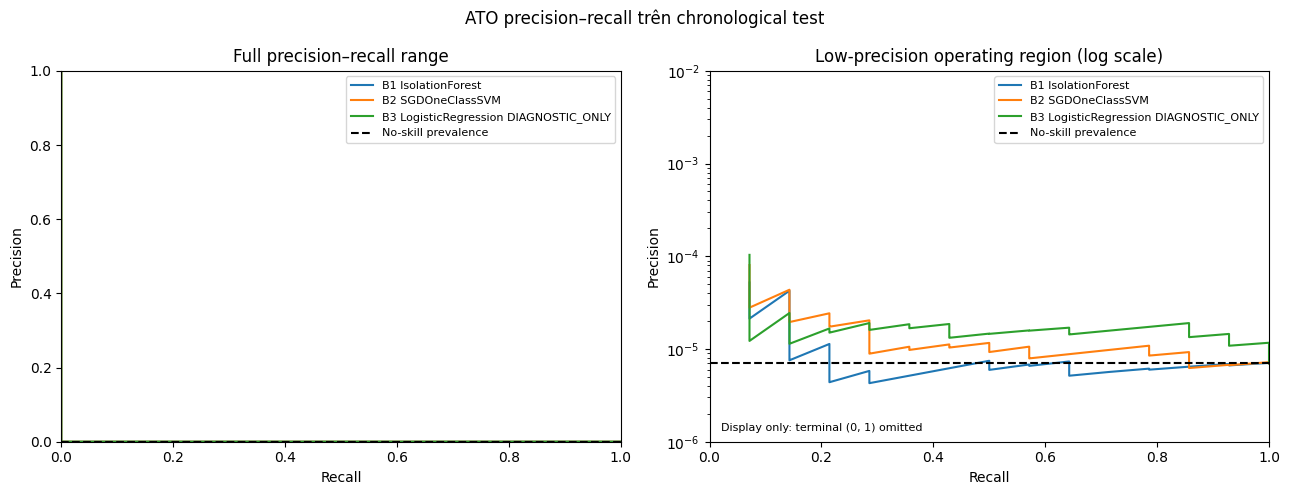

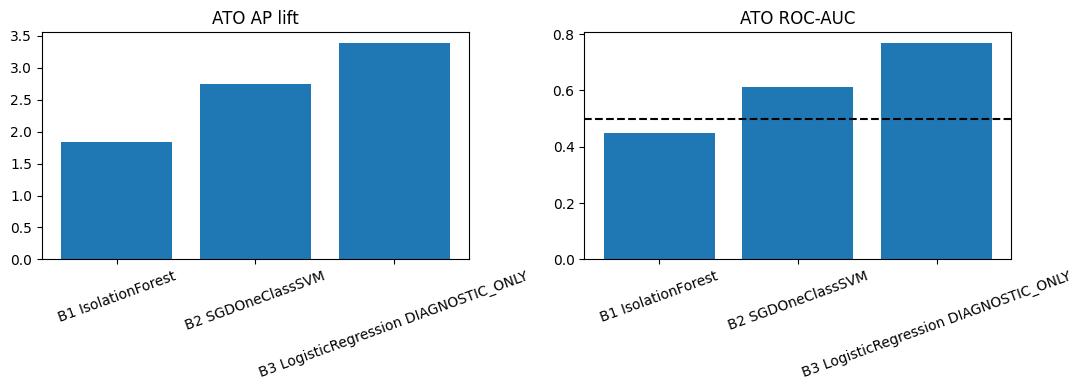

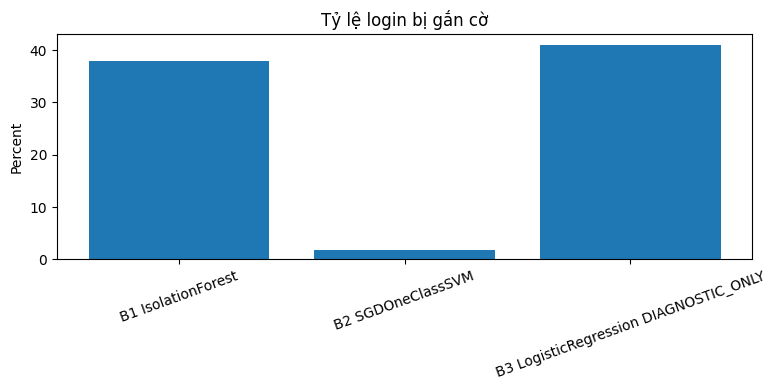

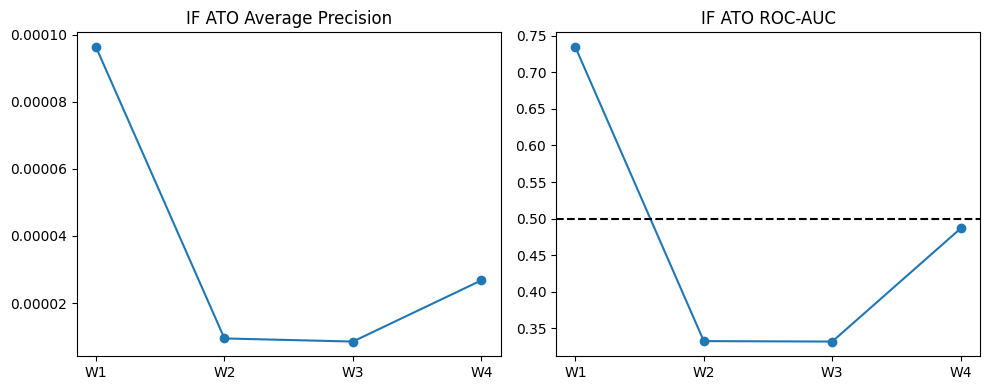

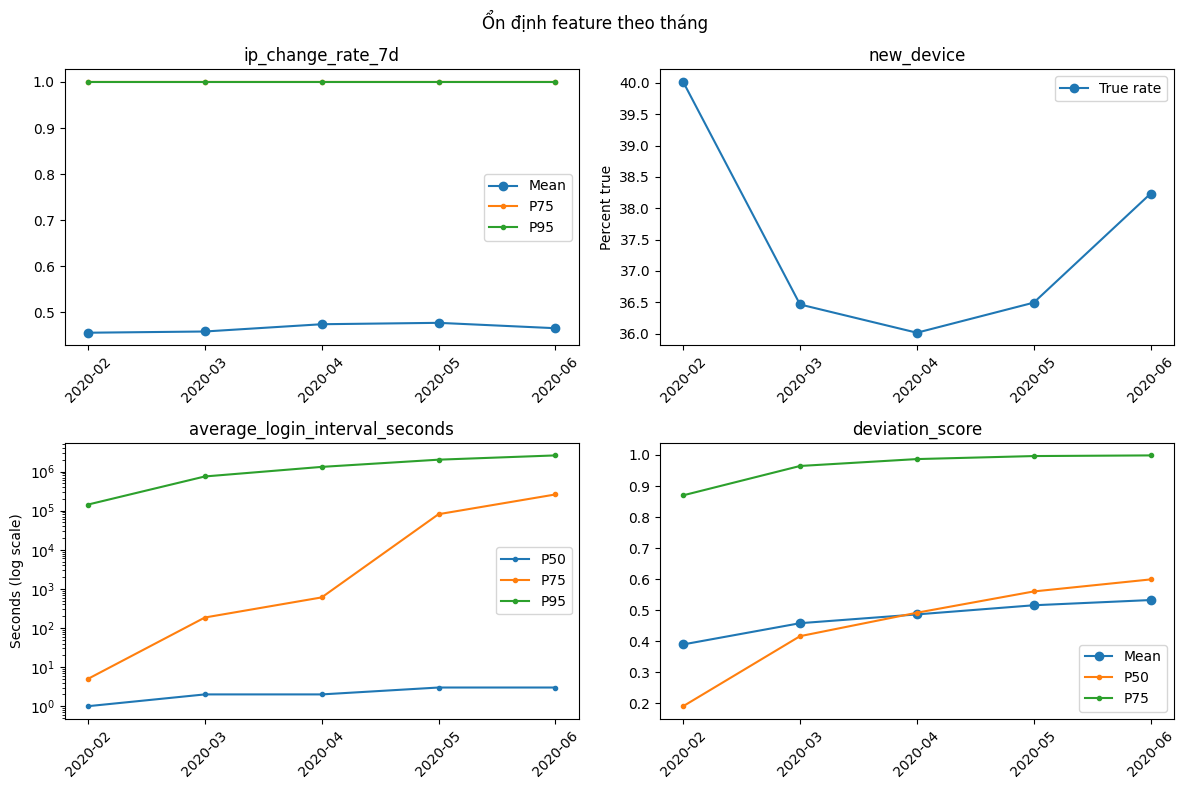

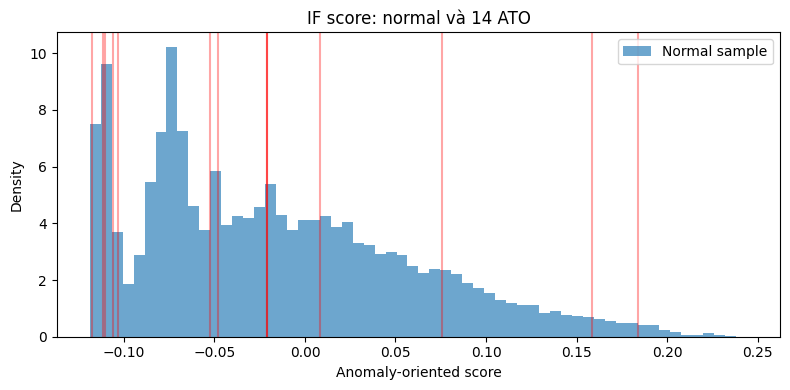

[2026-10-25T16:03:25.790697+00:00] figures: complete


In [16]:
progress('figures: start')
ato_truth = y_test['Is Account Takeover']

pr_curves = {}
for name in models:
    scores, _ = cached[(name, 'Is Account Takeover')]
    precision, recall, _ = precision_recall_curve(ato_truth, scores)
    pr_curves[name.split()[0]] = (precision, recall)
np.savez_compressed(
    OUTPUT_DIR / 'ato_pr_curves.npz',
    **{f'{key}_precision': value[0] for key, value in pr_curves.items()},
    **{f'{key}_recall': value[1] for key, value in pr_curves.items()},
    no_skill_prevalence=np.array([ato_truth.mean()]),
)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in models:
    precision, recall = pr_curves[name.split()[0]]
    axes[0].plot(recall, precision, label=name)
    display_mask = (precision > 0) & ~((recall == 0) & (precision == 1))
    axes[1].plot(recall[display_mask], precision[display_mask], label=name)
for ax in axes:
    ax.axhline(ato_truth.mean(), color='black', linestyle='--', label='No-skill prevalence')
    ax.set(xlabel='Recall', ylabel='Precision', xlim=(0, 1))
axes[0].set(title='Full precision–recall range', ylim=(0, 1))
axes[1].set(title='Low-precision operating region (log scale)', ylim=(1e-6, 1e-2))
axes[1].set_yscale('log')
axes[1].text(.02, 1.3e-6, 'Display only: terminal (0, 1) omitted', fontsize=8)
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
fig.suptitle('ATO precision–recall trên chronological test')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '01_ato_pr_curve.png', dpi=180)
plt.show()
plt.close(fig)

ato_overall = benchmark[(benchmark.target == 'Is Account Takeover') & (benchmark.model != 'B0 No-skill')]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(ato_overall.model, ato_overall.ap_lift); axes[0].set_title('ATO AP lift'); axes[0].tick_params(axis='x', rotation=20)
axes[1].bar(ato_overall.model, ato_overall.roc_auc); axes[1].axhline(.5, color='black', linestyle='--'); axes[1].set_title('ATO ROC-AUC'); axes[1].tick_params(axis='x', rotation=20)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / '02_ato_model_metrics.png', dpi=180); plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(ato_overall.model, ato_overall.flag_rate * 100); ax.set(ylabel='Percent', title='Tỷ lệ login bị gắn cờ')
ax.tick_params(axis='x', rotation=20); fig.tight_layout()
fig.savefig(OUTPUT_DIR / '03_flag_rate.png', dpi=180); plt.show(); plt.close(fig)

if_temporal = temporal_metrics[(temporal_metrics.target == 'Is Account Takeover') & (temporal_metrics.model == 'B1 IsolationForest')]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(if_temporal.window, if_temporal.average_precision, marker='o'); axes[0].set_title('IF ATO Average Precision')
axes[1].plot(if_temporal.window, if_temporal.roc_auc, marker='o'); axes[1].axhline(.5, color='black', linestyle='--'); axes[1].set_title('IF ATO ROC-AUC')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / '04_temporal_stability.png', dpi=180); plt.show(); plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(monthly_features.index, monthly_features.ip_change_rate_7d_mean, marker='o', label='Mean')
axes[0, 0].plot(monthly_features.index, monthly_features.ip_change_rate_7d_p75, marker='.', label='P75')
axes[0, 0].plot(monthly_features.index, monthly_features.ip_change_rate_7d_p95, marker='.', label='P95')
axes[0, 0].set_title('ip_change_rate_7d')
axes[0, 1].plot(monthly_features.index, monthly_features.new_device_true_rate * 100, marker='o', label='True rate')
axes[0, 1].set(title='new_device', ylabel='Percent true')
axes[1, 0].plot(monthly_features.index, monthly_features.average_login_interval_seconds_p50, marker='.', label='P50')
axes[1, 0].plot(monthly_features.index, monthly_features.average_login_interval_seconds_p75, marker='.', label='P75')
axes[1, 0].plot(monthly_features.index, monthly_features.average_login_interval_seconds_p95, marker='.', label='P95')
axes[1, 0].set(title='average_login_interval_seconds', ylabel='Seconds (log scale)')
axes[1, 0].set_yscale('log')
axes[1, 1].plot(monthly_features.index, monthly_features.deviation_score_mean, marker='o', label='Mean')
axes[1, 1].plot(monthly_features.index, monthly_features.deviation_score_p50, marker='.', label='P50')
axes[1, 1].plot(monthly_features.index, monthly_features.deviation_score_p75, marker='.', label='P75')
axes[1, 1].set_title('deviation_score')
for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)
    ax.legend()
fig.suptitle('Ổn định feature theo tháng'); fig.tight_layout()
fig.savefig(OUTPUT_DIR / '05_feature_stability.png', dpi=180)
plt.show()
plt.close(fig)

rng = np.random.default_rng(RANDOM_STATE)
normal_scores = if_score[ato_truth.to_numpy() == 0]
normal_sample = rng.choice(normal_scores, size=min(200_000, len(normal_scores)), replace=False)
ato_scores = if_score[ato_truth.to_numpy() == 1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(normal_sample, bins=60, density=True, alpha=.65, label='Normal sample')
for value in ato_scores:
    ax.axvline(value, color='red', alpha=.35)
ax.set(title=f'IF score: normal và {len(ato_scores)} ATO', xlabel='Anomaly-oriented score', ylabel='Density')
ax.legend(); fig.tight_layout(); fig.savefig(OUTPUT_DIR / '06_error_analysis.png', dpi=180); plt.show(); plt.close(fig)
progress('figures: complete')

## 14 — Artifact thực nghiệm và metadata

`MinMaxScaler(clip=True)` chỉ chuẩn hóa score cho API `[0,1]`; nó không scale input và không biến score thành xác suất. Artifact không được tự động promote.

In [17]:
progress('artifact export: start')
isolation_forest = models['B1 IsolationForest']
train_oriented_score = -isolation_forest.decision_function(X_train)
score_scaler = MinMaxScaler(clip=True).fit(train_oriented_score.reshape(-1, 1))
bundle = {
    'model': isolation_forest, 'score_scaler': score_scaler,
    'features': FEATURES, 'version': MODEL_VERSION,
    'score_input': '-decision_function',
    'feature_semantics_version': FEATURE_SEMANTICS_VERSION,
}
model_path = OUTPUT_DIR / f'{MODEL_VERSION}.joblib'
joblib.dump(bundle, model_path)

ato_if = benchmark[(benchmark.target == TARGETS[0]) & (benchmark.model == 'B1 IsolationForest')].iloc[0]
metadata = {
    'version': MODEL_VERSION, 'status': 'experimental', 'is_production': False,
    'algorithm': 'sklearn.ensemble.IsolationForest', 'features': FEATURES,
    'feature_semantics_version': FEATURE_SEMANTICS_VERSION,
    'training_labels_used': False, 'model_parameters': isolation_forest.get_params(),
    'normalization': 'MinMaxScaler(clip=True) fitted on training -decision_function',
    'score_semantics': 'higher means more anomalous; not a probability',
    'rows_loaded': int(len(model_data)), 'train_rows': int(len(X_train)),
    'test_rows': int(len(X_test)), 'cutoff_utc': cutoff.isoformat(),
    'test_ato_positives': int(y_test[TARGETS[0]].sum()),
    'ato_isolation_forest': {key: (None if pd.isna(ato_if[key]) else float(ato_if[key]))
                             for key in ['average_precision', 'ap_lift', 'roc_auc', 'precision', 'recall', 'f1', 'flag_rate']},
    'baseline_10m': BASELINE_10M,
    'python_version': platform.python_version(), 'sklearn_version': sklearn.__version__,
    'numpy_version': np.__version__, 'dataset': 'Wiefling et al., DOI 10.5281/zenodo.6782156',
    'dataset_warning': 'Synthetic research data; not for production IDS use',
}
(OUTPUT_DIR / 'experiment_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
progress(f'artifact export: complete {model_path.name}')

[2026-10-25T16:03:25.838346+00:00] artifact export: start
[2026-10-25T16:03:39.535826+00:00] heartbeat: notebook active
[2026-10-25T16:04:08.466961+00:00] artifact export: complete v1.1-isolation-forest-rba-corrected-experimental.joblib


## 15 — Danh mục kết quả

In [18]:
progress('final export inventory')
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name, path.stat().st_size)
heartbeat_stop.set()
progress('notebook complete')

[2026-10-25T16:04:08.515720+00:00] final export inventory
01_ato_pr_curve.png 107476
02_ato_model_metrics.png 71437
03_flag_rate.png 65620
04_temporal_stability.png 78041
05_feature_stability.png 188327
06_error_analysis.png 34108
ato_pr_curves.npz 22444168
benchmark_metrics.csv 2852
error_analysis_sample.csv 61372
experiment_metadata.json 2010
feature_stability.csv 885
feature_statistics.csv 4782
temporal_metrics.csv 9489
univariate_feature_metrics.csv 891
v1.1-isolation-forest-rba-corrected-experimental.joblib 1320347
v6_reproduction_check.csv 1086
[2026-10-25T16:04:08.518119+00:00] notebook complete
